# 03 — Modeling

Step 3: preprocessing `Pipeline` + Logistic Regression.
Step 4: Random Forest, SVM and Gradient Boosting.
Step 5: CV stability and the main metric.
Step 6: hyperparameter tuning.

All models are scored with the same 5-fold CV on the train set and compared with the baselines from `02_baseline.ipynb`.

Rules
- All preprocessing sits inside the `Pipeline`, so it is fitted on train folds only (no leakage).
- The test set is not touched until the final evaluation (step 7).
- Later steps (CV analysis, tuning, importance) continue in this notebook.

Run `02_baseline.ipynb` first (it creates `reports/baseline_cv_results.csv`).

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
sys.path.append(str(Path('..').resolve()))
from src.data import RANDOM_STATE, get_split
from src.business import (CampaignAssumptions, break_even_precision,confusion_counts, expected_profit)
from src.evaluate import (cv_fold_scores, cv_scores, format_table,make_cv, oof_predictions)
from src.evaluate import SCORERS
from src.models import build_model_zoo
from src.tuning import make_search
from src.pipeline import build_pipeline, split_columns
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 50)
REPORT_DIR = Path('../reports')
FIG_DIR = REPORT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

## 1. Data

In [2]:
X_train, X_test, y_train, y_test = get_split()
num_cols, cat_cols = split_columns(X_train)

print('train:', X_train.shape, '| numeric:', len(num_cols), '| categorical:', len(cat_cols))
print('numeric:', num_cols)

train: (5634, 19) | numeric: 3 | categorical: 16
numeric: ['tenure', 'MonthlyCharges', 'TotalCharges']


## 2. Pipeline

- Numeric: median imputer, then `StandardScaler`.
- Categorical (incl. `SeniorCitizen`): most-frequent imputer, then `OneHotEncoder(handle_unknown='ignore', drop='if_binary')`.
- Model: `LogisticRegression`.

In [3]:
pipe = build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), X_train)
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output o

## 3. Logistic Regression (5-fold CV on train)

Two versions: default, and `class_weight='balanced'` to handle the 26.5% churn rate.

In [4]:
models = {
    'LogReg': build_pipeline(
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), X_train),
    'LogReg (balanced)': build_pipeline(
        LogisticRegression(max_iter=1000, class_weight='balanced',
                           random_state=RANDOM_STATE), X_train),
}

cv = make_cv()
records = {name: cv_scores(m, X_train, y_train, cv=cv) for name, m in models.items()}

results = pd.DataFrame(records).T
results.index.name = 'model'
results.round(4).to_csv(REPORT_DIR / 'cv_results.csv')

display(format_table(results))
display((results['train_f1_mean'] - results['f1_mean']).round(3).rename('train F1 - CV F1'))

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
LogReg,0.802 +/- 0.012,0.653 +/- 0.027,0.544 +/- 0.041,0.593 +/- 0.030,0.846 +/- 0.013,0.662 +/- 0.019
LogReg (balanced),0.749 +/- 0.015,0.518 +/- 0.019,0.803 +/- 0.036,0.629 +/- 0.022,0.846 +/- 0.012,0.660 +/- 0.020


model
LogReg               0.010
LogReg (balanced)    0.004
Name: train F1 - CV F1, dtype: float64

**Result:** plain LogReg: F1 0.59, recall 0.54, precision 0.65, ROC-AUC 0.85, PR-AUC 0.66. Train F1 is only ~0.01 above CV F1, so no overfitting.

`class_weight='balanced'` trades precision (0.52) for recall (0.80) and raises F1 to 0.63. ROC-AUC and PR-AUC stay the same: ranking quality is unchanged, it mostly moves the operating point.

## 4. Comparison with baselines

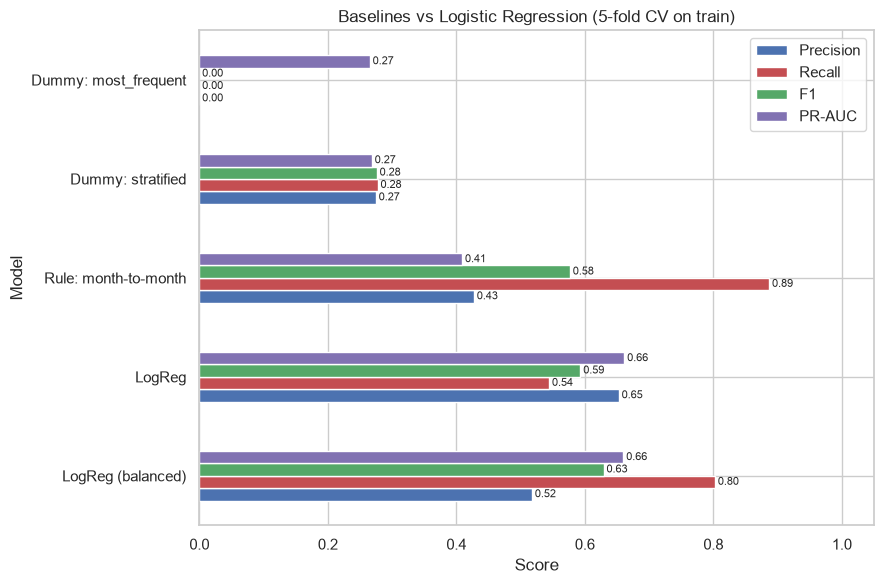

In [5]:
baselines = pd.read_csv(REPORT_DIR / 'baseline_cv_results.csv', index_col='model')
compare = pd.concat([baselines, results[baselines.columns]])

plot_df = compare[['precision_mean', 'recall_mean', 'f1_mean', 'pr_auc_mean']].copy()
plot_df.columns = ['Precision', 'Recall', 'F1', 'PR-AUC']

ax = plot_df.iloc[::-1].plot(kind='barh', figsize=(9, 6),
                             color=['#4C72B0', '#C44E52', '#55A868', '#8172B2'])
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=8, padding=2)
ax.set_title('Baselines vs Logistic Regression (5-fold CV on train)')
ax.set_xlabel('Score')
ax.set_ylabel('Model')
ax.set_xlim(0, 1.05)
save_fig('11_model_comparison_logreg')
plt.show()

**Result:** both LogReg versions clearly beat the baselines on PR-AUC (0.66 vs 0.41) and ROC-AUC (0.85 vs 0.73). On F1, plain LogReg (0.59) is barely above the month-to-month rule (0.58); the balanced version (0.63) is clearly better.

## 5. Coefficients

Fitted on the train set only, for interpretation.

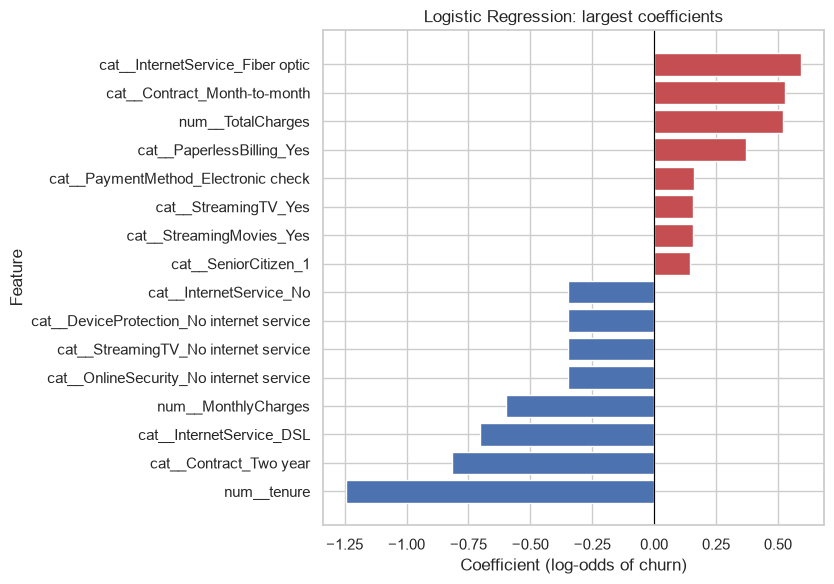

In [6]:
final = build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), X_train).fit(X_train, y_train)

names = final.named_steps['pre'].get_feature_names_out()
coef = pd.Series(final.named_steps['model'].coef_[0], index=names).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])

fig, ax = plt.subplots(figsize=(8.5, 6))
ax.barh(top.index, top.values, color=np.where(top.values < 0, '#4C72B0', '#C44E52'))
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Logistic Regression: largest coefficients')
ax.set_xlabel('Coefficient (log-odds of churn)')
ax.set_ylabel('Feature')
save_fig('12_logreg_coefficients')
plt.show()

**Result:** churn goes up with fiber optic, month-to-month contract, paperless billing and electronic check; it goes down with long tenure, a two-year contract and DSL.

Do not read single coefficients alone: `MonthlyCharges` is negative and `TotalCharges` positive because both are correlated with `tenure` and the service columns. Use permutation importance in step 7.

## 6. More models (step 4)

Random Forest, SVM (RBF) and Histogram Gradient Boosting, each with and without `class_weight='balanced'`. Same pipeline, same 5-fold CV, default hyperparameters (tuning is step 6).

In [7]:
zoo = build_model_zoo(X_train)
new_models = {n: m for n, m in zoo.items() if n not in results.index}
new_records = {}
for name, model in new_models.items():
    new_records[name] = cv_scores(model, X_train, y_train, cv=cv)
    print(f"done: {name} ({new_records[name]['fit_time_s']:.1f}s per fit)")

new_results = pd.DataFrame(new_records).T
new_results.index.name = 'model'

all_results = pd.concat([results, new_results])
all_results.round(4).to_csv(REPORT_DIR / 'cv_results.csv')

display(format_table(all_results))

done: RandomForest (0.8s per fit)
done: RandomForest (balanced) (0.9s per fit)
done: SVM-RBF (0.5s per fit)
done: SVM-RBF (balanced) (0.6s per fit)
done: HistGB (0.4s per fit)
done: HistGB (balanced) (0.7s per fit)


,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
LogReg,0.802 +/- 0.012,0.653 +/- 0.027,0.544 +/- 0.041,0.593 +/- 0.030,0.846 +/- 0.013,0.662 +/- 0.019
LogReg (balanced),0.749 +/- 0.015,0.518 +/- 0.019,0.803 +/- 0.036,0.629 +/- 0.022,0.846 +/- 0.012,0.660 +/- 0.020
RandomForest,0.787 +/- 0.013,0.630 +/- 0.035,0.480 +/- 0.028,0.544 +/- 0.028,0.822 +/- 0.011,0.614 +/- 0.028
RandomForest (balanced),0.777 +/- 0.009,0.569 +/- 0.014,0.654 +/- 0.031,0.609 +/- 0.021,0.824 +/- 0.011,0.612 +/- 0.029
SVM-RBF,0.804 +/- 0.007,0.678 +/- 0.023,0.499 +/- 0.021,0.574 +/- 0.015,0.797 +/- 0.017,0.637 +/- 0.021
SVM-RBF (balanced),0.752 +/- 0.013,0.521 +/- 0.017,0.783 +/- 0.039,0.626 +/- 0.022,0.826 +/- 0.011,0.602 +/- 0.029
HistGB,0.795 +/- 0.009,0.644 +/- 0.023,0.512 +/- 0.028,0.570 +/- 0.023,0.836 +/- 0.005,0.647 +/- 0.021
HistGB (balanced),0.767 +/- 0.010,0.546 +/- 0.014,0.731 +/- 0.022,0.625 +/- 0.017,0.837 +/- 0.009,0.649 +/- 0.019


In [8]:
ranking = (all_results[['precision_mean', 'recall_mean', 'f1_mean', 'f1_std','roc_auc_mean', 'pr_auc_mean', 'fit_time_s']].sort_values('f1_mean', ascending=False).round(3))
display(ranking)

,precision_mean,recall_mean,f1_mean,f1_std,roc_auc_mean,pr_auc_mean,fit_time_s
model,,,,,,,
LogReg (balanced),0.518,0.803,0.629,0.022,0.846,0.660,0.074
SVM-RBF (balanced),0.521,0.783,0.626,0.022,0.826,0.602,0.629
HistGB (balanced),0.546,0.731,0.625,0.017,0.837,0.649,0.669
RandomForest (balanced),0.569,0.654,0.609,0.021,0.824,0.612,0.862
LogReg,0.653,0.544,0.593,0.030,0.846,0.662,0.095
SVM-RBF,0.678,0.499,0.574,0.015,0.797,0.637,0.513
HistGB,0.644,0.512,0.570,0.023,0.836,0.647,0.438
RandomForest,0.630,0.480,0.544,0.028,0.822,0.614,0.832


**Result:** the three balanced models are tied on F1 (LogReg 0.63, SVM 0.63, HistGB 0.63; the CV std is ~0.02, so the gaps are noise). Without class weights all models drop to F1 0.54-0.59 because recall falls to ~0.5.

On ranking quality, LogReg is best or tied: ROC-AUC 0.85 / PR-AUC 0.66, vs HistGB 0.84 / 0.65, SVM 0.80-0.83 / 0.60-0.64 and Random Forest 0.82 / 0.61.

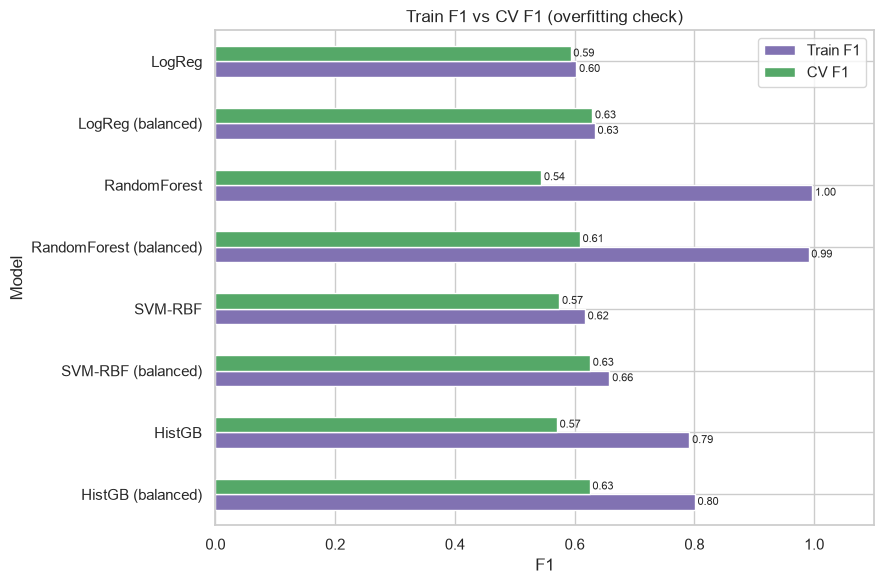

In [9]:
gap_df = all_results[['train_f1_mean', 'f1_mean']].rename(columns={'train_f1_mean': 'Train F1', 'f1_mean': 'CV F1'})

ax = gap_df.iloc[::-1].plot(kind='barh', figsize=(9, 6), color=['#8172B2', '#55A868'])
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=8, padding=2)
ax.set_title('Train F1 vs CV F1 (overfitting check)')
ax.set_xlabel('F1')
ax.set_ylabel('Model')
ax.set_xlim(0, 1.1)
save_fig('13_train_vs_cv_f1')
plt.show()

**Result:** Random Forest memorizes the train folds (train F1 0.997 vs CV 0.54), and HistGB overfits moderately (train F1 ~0.80 vs CV 0.57-0.63). LogReg and SVM show almost no gap. Class weights barely help Random Forest because fully grown trees have pure leaves.

Tuning (step 6) should limit tree depth / leaf size for Random Forest and regularize HistGB.

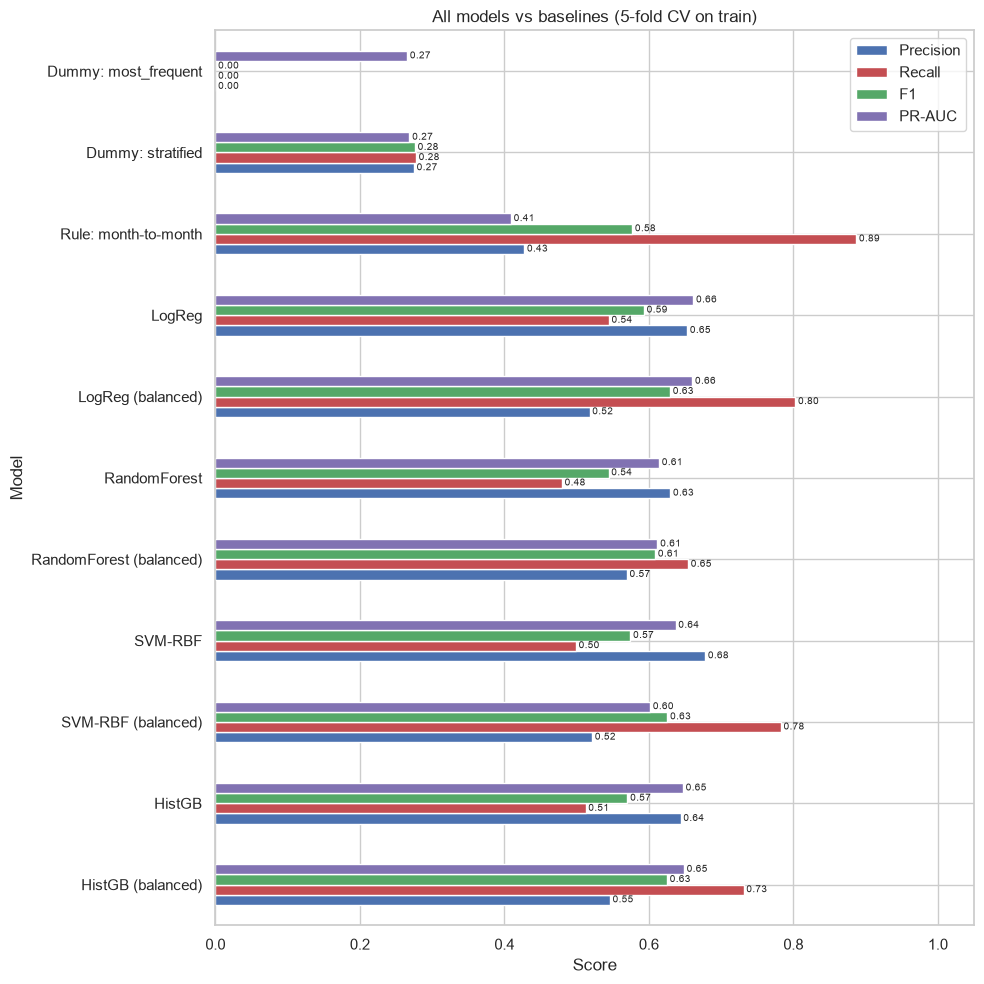

In [10]:
compare_all = pd.concat([baselines, all_results[baselines.columns]])

plot_df = compare_all[['precision_mean', 'recall_mean', 'f1_mean', 'pr_auc_mean']].copy()
plot_df.columns = ['Precision', 'Recall', 'F1', 'PR-AUC']

ax = plot_df.iloc[::-1].plot(kind='barh', figsize=(10, 10),color=['#4C72B0', '#C44E52', '#55A868', '#8172B2'])
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=7, padding=2)
ax.set_title('All models vs baselines (5-fold CV on train)')
ax.set_xlabel('Score')
ax.set_ylabel('Model')
ax.set_xlim(0, 1.05)
save_fig('14_all_models_comparison')
plt.show()

**Result:** every model beats every baseline on PR-AUC and ROC-AUC. Balanced versions trade precision for recall (recall 0.73-0.80, precision ~0.52-0.55); unbalanced versions do the opposite (recall ~0.5, precision ~0.65).

Takeaway: a more complex model does not win here. Simple LogReg is at least as good as the ensembles, which is common for small tabular data.

## 7. Shortlist for tuning

| Model | Why |
|---|---|
| LogReg | best ranking quality (ROC-AUC, PR-AUC), simplest, interpretable; tune `C` |
| Random Forest | most overfit, so it has the most to gain from depth / leaf limits |
| HistGB | competitive AUC; regularization may close the train/CV gap |
| SVM (RBF) | not tuned: no better than LogReg, slower, no probabilities; optional `RandomizedSearchCV` |

Always compare with and without `class_weight`.

## 8. Stability across folds (step 5)

Per-fold scores for every model (same 5 folds), then paired differences against `LogReg (balanced)`.

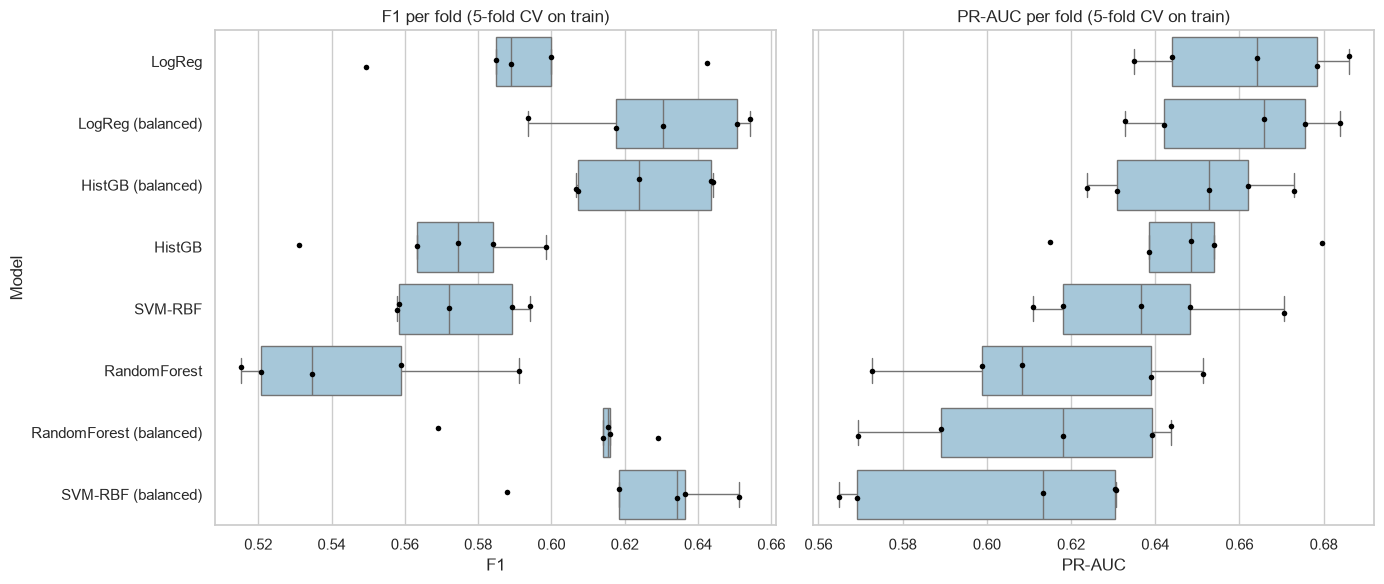

In [11]:
fold_scores = {name: cv_fold_scores(model, X_train, y_train, cv=cv)
               for name, model in zoo.items()}

fold_df = pd.concat(fold_scores, names=['model', 'fold']).reset_index()
order = fold_df.groupby('model')['pr_auc'].mean().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, metric, title in zip(axes, ['f1', 'pr_auc'], ['F1', 'PR-AUC']):
    sns.boxplot(data=fold_df, x=metric, y='model', order=order, ax=ax,color='#9ecae1', fliersize=0)
    sns.stripplot(data=fold_df, x=metric, y='model', order=order, ax=ax,color='black', size=4)
    ax.set_title(f'{title} per fold (5-fold CV on train)')
    ax.set_xlabel(title)
    ax.set_ylabel('Model')
save_fig('15_fold_stability')
plt.show()

**Result:** `LogReg (balanced)` F1 ranges from 0.59 to 0.65 across folds, a swing as large as the gaps between the top models. Random Forest is below it in every fold.

In [12]:
ref = 'LogReg (balanced)'
rows = []
for name, scores in fold_scores.items():
    if name == ref:
        continue
    d = scores[['f1', 'pr_auc']] - fold_scores[ref][['f1', 'pr_auc']]
    rows.append({
        'model': name,
        'F1 diff (mean)': d['f1'].mean(), 'F1 diff (std)': d['f1'].std(),
        'F1 folds won': int((d['f1'] > 0).sum()),
        'PR-AUC diff (mean)': d['pr_auc'].mean(), 'PR-AUC diff (std)': d['pr_auc'].std(),
        'PR-AUC folds won': int((d['pr_auc'] > 0).sum()),
    })
paired = pd.DataFrame(rows).set_index('model').round(3)
display(paired)

,F1 diff (mean),F1 diff (std),F1 folds won,PR-AUC diff (mean),PR-AUC diff (std),PR-AUC folds won
model,,,,,,
LogReg,-0.036,0.023,0,0.001,0.002,4
RandomForest,-0.085,0.041,0,-0.046,0.021,0
RandomForest (balanced),-0.021,0.018,0,-0.048,0.018,0
SVM-RBF,-0.055,0.028,0,-0.023,0.009,0
SVM-RBF (balanced),-0.004,0.010,3,-0.058,0.016,0
HistGB,-0.059,0.027,0,-0.013,0.010,0
HistGB (balanced),-0.004,0.018,2,-0.011,0.007,0


**Result (differences vs `LogReg (balanced)`, 5 paired folds):**
- F1: `SVM (balanced)` and `HistGB (balanced)` are a tie (diff -0.004, std <= 0.014). Every other model loses in all 5 folds.
- PR-AUC: no model is clearly better. `LogReg` is identical (+0.001); HistGB is ~0.014 lower, SVM 0.02-0.06 lower, Random Forest ~0.05 lower.

With only 5 folds this is moderate evidence, not proof.

## 9. Choosing the main metric

Business setup (illustrative numbers, replace with real company figures):

| Assumption | Value |
|---|---|
| Value of a retained customer (`V`) | $500 |
| Cost of one retention offer (`C`) | $50 |
| Offer success rate for churners (`s`) | 30% |

Profit of a campaign = `TP * (s*V - C) - FP * C`. It makes money only if precision > `C / (s*V)`.

In [13]:
assump = CampaignAssumptions(value=500, cost=50, success_rate=0.3)
print(f'break-even precision: {break_even_precision(assump):.2f}')

sens = pd.DataFrame(
    {f'C = ${c}': {f's = {int(s * 100)}%': break_even_precision(
        CampaignAssumptions(value=500, cost=c, success_rate=s))
        for s in (0.2, 0.3, 0.5)} for c in (25, 50, 100)}).round(2)
display(sens)

break-even precision: 0.33


,C = $25,C = $50,C = $100
s = 20%,0.25,0.50,1.00
s = 30%,0.17,0.33,0.67
s = 50%,0.10,0.20,0.40


**Result:** with these assumptions precision must exceed 0.33. Every model does (0.52-0.68). A missed churner (FN) loses the chance to save `V`; a false alarm (FP) costs only `C`. So recall matters more, but precision cannot be ignored: contacting everyone loses money. The break-even precision moves a lot with the assumptions (0.10 to 1.00 in the table), so the real numbers matter.

,tp,fp,fn,tn,precision,recall,profit_per_1000
model,,,,,,,
LogReg (balanced),1200,1118,295,3021,0.518,0.803,11377.352
HistGB (balanced),1093,909,402,3230,0.546,0.731,11332.978
SVM-RBF (balanced),1170,1074,325,3065,0.521,0.783,11235.357
RandomForest (balanced),978,739,517,3400,0.570,0.654,10800.497
LogReg,814,433,681,3706,0.653,0.544,10605.254
SVM-RBF,746,356,749,3783,0.677,0.499,10081.647
HistGB,766,424,729,3715,0.644,0.512,9833.156
RandomForest,717,423,778,3716,0.629,0.480,8972.311
Contact nobody,0,0,1495,4139,NaN,0.000,0.000


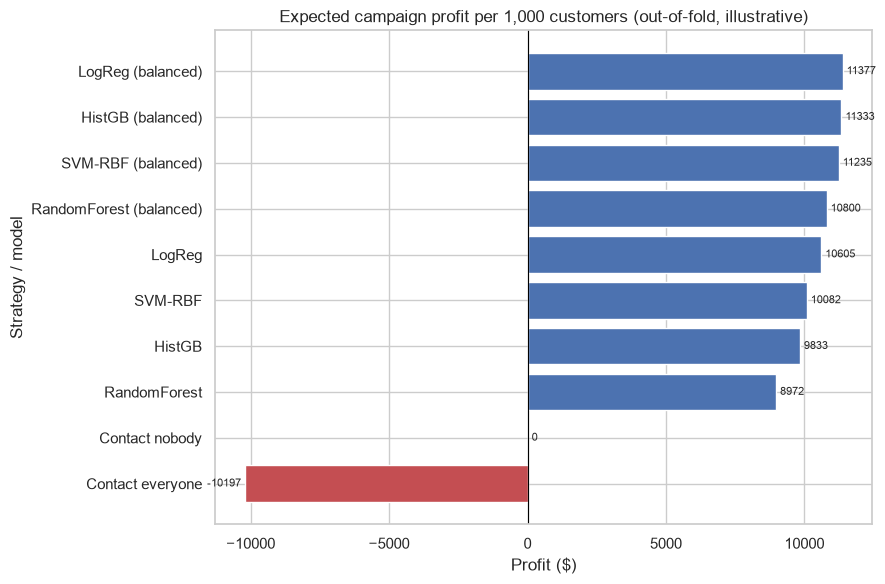

In [14]:
n = len(y_train)
pos = int(y_train.sum())

rows = []
for name, model in zoo.items():
    c = confusion_counts(y_train, oof_predictions(model, X_train, y_train, cv=cv))
    rows.append({'model': name, **c})
rows.append({'model': 'Contact everyone', 'tp': pos, 'fp': n - pos, 'fn': 0, 'tn': 0})
rows.append({'model': 'Contact nobody', 'tp': 0, 'fp': 0, 'fn': pos, 'tn': n - pos})

profit = pd.DataFrame(rows).set_index('model')
profit['precision'] = profit['tp'] / (profit['tp'] + profit['fp']).replace(0, np.nan)
profit['recall'] = profit['tp'] / (profit['tp'] + profit['fn'])
profit['profit_per_1000'] = [expected_profit(r.tp, r.fp, assump) / n * 1000
                             for r in profit.itertuples()]
profit = profit.sort_values('profit_per_1000', ascending=False)
profit.round(3).to_csv(REPORT_DIR / 'expected_profit.csv')
display(profit.round(3))

fig, ax = plt.subplots(figsize=(9, 6))
colors = np.where(profit['profit_per_1000'] < 0, '#C44E52', '#4C72B0')
bars = ax.barh(profit.index[::-1], profit['profit_per_1000'].values[::-1],
               color=colors[::-1])
ax.bar_label(bars, fmt='%.0f', padding=3, fontsize=8)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Expected campaign profit per 1,000 customers (out-of-fold, illustrative)')
ax.set_xlabel('Profit ($)')
ax.set_ylabel('Strategy / model')
save_fig('16_expected_profit')
plt.show()

**Result:** per 1,000 customers (~265 churners), contacting everyone loses ~$10,200 and the best models earn ~$11,400. The three balanced models are within ~1.3% of each other (a tie). Unbalanced versions earn $0.8k-2.5k less because they miss churners (recall ~0.5).

The dollar figures come from made-up assumptions; the method is the point.

### Decision

**Main metric: PR-AUC.** Missing a churner costs the customer's value, a false alarm costs only one offer, so recall matters, but precision decides whether the campaign makes money. PR-AUC covers both and needs no threshold, so it compares models fairly: class weights and thresholds move the operating point, not the ranking quality. The threshold is then chosen by expected profit (step 7).

| Role | Metric |
|---|---|
| Model selection and tuning (step 6) | PR-AUC (CV mean +/- std) |
| Operating point (step 7) | threshold by expected profit; report precision, recall, F1 there |
| Reporting | F1, recall, precision, ROC-AUC, confusion matrix |
| Not used for ranking | accuracy |

## 10. Hyperparameter tuning (step 6)

- Selection metric: PR-AUC (`scoring='average_precision'`). All other metrics are recorded but do not decide the winner.
- Tuned on the train set with the same 5-fold CV. The best CV score is slightly optimistic; the unbiased estimate comes from the test set in step 7.

| Model | Search | Space |
|---|---|---|
| LogReg | `GridSearchCV` (14) | `C` in 0.01-10, `class_weight` None/balanced |
| Random Forest | `GridSearchCV` (24) | `min_samples_leaf` 5/10/20/40, `max_depth` 6/10/None, `class_weight` |
| HistGB | `RandomizedSearchCV` (40) | learning rate, iterations, leaves, leaf size, L2, `class_weight` |

HistGB has too many parameters for a full grid, so it uses random search. The next cell takes a few minutes (Random Forest is the slowest).

In [15]:
searches = {}
for name in ['LogReg', 'RandomForest', 'HistGB']:
    search = make_search(name, X_train, cv=cv)
    search.fit(X_train, y_train)
    searches[name] = search
    print(f'{name}: best CV PR-AUC = {search.best_score_:.4f}')

LogReg: best CV PR-AUC = 0.6616
RandomForest: best CV PR-AUC = 0.6654
HistGB: best CV PR-AUC = 0.6692


In [16]:
rows = []
for name, search in searches.items():
    cr = pd.DataFrame(search.cv_results_)
    b = search.best_index_
    rec = {'model': f'{name} (tuned)'}
    for m in SCORERS:
        rec[f'{m}_mean'] = cr.loc[b, f'mean_test_{m}']
        rec[f'{m}_std'] = cr.loc[b, f'std_test_{m}']
    rows.append(rec)
tuned = pd.DataFrame(rows).set_index('model')
tuned.round(4).to_csv(REPORT_DIR / 'tuned_cv_results.csv')

default = all_results.loc[['LogReg', 'RandomForest', 'HistGB'], tuned.columns]
display(format_table(pd.concat([default, tuned])))

best_params = {
    n: {k: (float(v) if isinstance(v, np.floating) else v)
        for k, v in s.best_params_.items()}
    for n, s in searches.items()
}
with open(REPORT_DIR / 'best_params.json', 'w') as f:
    json.dump(best_params, f, indent=2)
print(json.dumps(best_params, indent=2))

keep = ['mean_test_pr_auc', 'std_test_pr_auc', 'mean_test_f1', 'mean_test_recall',
        'mean_test_precision', 'rank_test_pr_auc']
candidates = pd.concat({
    n: pd.DataFrame(s.cv_results_)[
        [c for c in s.cv_results_ if c.startswith('param_')] + keep]
    for n, s in searches.items()}, names=['model', 'candidate']).reset_index(level=0)
candidates.round(4).to_csv(REPORT_DIR / 'tuning_candidates.csv', index=False)

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
LogReg,0.802 +/- 0.012,0.653 +/- 0.027,0.544 +/- 0.041,0.593 +/- 0.030,0.846 +/- 0.013,0.662 +/- 0.019
RandomForest,0.787 +/- 0.013,0.630 +/- 0.035,0.480 +/- 0.028,0.544 +/- 0.028,0.822 +/- 0.011,0.614 +/- 0.028
HistGB,0.795 +/- 0.009,0.644 +/- 0.023,0.512 +/- 0.028,0.570 +/- 0.023,0.836 +/- 0.005,0.647 +/- 0.021
LogReg (tuned),0.803 +/- 0.013,0.655 +/- 0.028,0.547 +/- 0.041,0.596 +/- 0.031,0.846 +/- 0.013,0.662 +/- 0.019
RandomForest (tuned),0.804 +/- 0.008,0.685 +/- 0.030,0.484 +/- 0.013,0.567 +/- 0.014,0.848 +/- 0.010,0.665 +/- 0.021
HistGB (tuned),0.804 +/- 0.008,0.669 +/- 0.026,0.520 +/- 0.023,0.585 +/- 0.017,0.849 +/- 0.012,0.669 +/- 0.021


{
  "LogReg": {
    "model__C": 3,
    "model__class_weight": null
  },
  "RandomForest": {
    "model__class_weight": null,
    "model__max_depth": null,
    "model__min_samples_leaf": 20
  },
  "HistGB": {
    "model__class_weight": null,
    "model__l2_regularization": 0.1,
    "model__learning_rate": 0.02611554269799446,
    "model__max_iter": 300,
    "model__max_leaf_nodes": 4,
    "model__min_samples_leaf": 50
  }
}


**Result (CV PR-AUC, default -> tuned):** Random Forest 0.614 -> 0.665 (+0.05), HistGB 0.647 -> 0.669 (+0.02), LogReg 0.661 -> 0.662 (no real change). After tuning all three sit at 0.66-0.67 with a CV std of ~0.02, so they are a tie.

Best settings: Random Forest gains most from limiting leaf size (`min_samples_leaf=20`); HistGB prefers small trees (`max_leaf_nodes=4`) with a low learning rate (~0.03) and 300 iterations; LogReg `C=3`.

All three winners use `class_weight=None`: PR-AUC does not reward class weights. The operating point (precision vs recall) is set by the threshold in step 7, so F1 / recall here are not comparable to the balanced rows above.

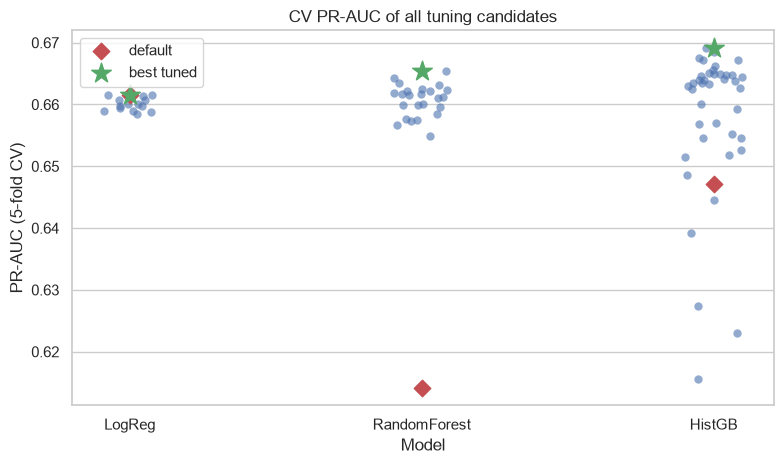

In [17]:
cand = pd.concat({n: pd.DataFrame(s.cv_results_)[['mean_test_pr_auc']]
                  for n, s in searches.items()},
                 names=['model', 'i']).reset_index()
order = list(searches)
defaults = all_results.loc[order, 'pr_auc_mean']
best_scores = [searches[n].best_score_ for n in order]

fig, ax = plt.subplots(figsize=(8, 4.8))
sns.stripplot(data=cand, x='model', y='mean_test_pr_auc', order=order,
              color='#4C72B0', alpha=0.6, size=6, ax=ax)
ax.scatter(order, defaults.values, marker='D', s=70, color='#C44E52',
           zorder=3, label='default')
ax.scatter(order, best_scores, marker='*', s=220, color='#55A868',
           zorder=3, label='best tuned')
ax.set_title('CV PR-AUC of all tuning candidates')
ax.set_xlabel('Model')
ax.set_ylabel('PR-AUC (5-fold CV)')
ax.legend()
save_fig('17_tuning_candidates')
plt.show()

**Result:** tuning matters for Random Forest and (less) HistGB; for LogReg all 14 candidates are within 0.658-0.662. The differences between the tuned models are smaller than the fold-to-fold noise.

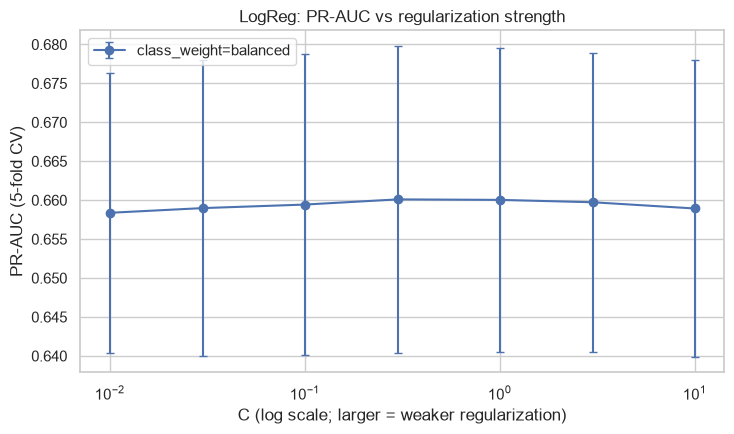

In [18]:
lr = pd.DataFrame(searches['LogReg'].cv_results_)
lr['C'] = lr['param_model__C'].astype(float)
lr['class_weight'] = lr['param_model__class_weight'].astype(str)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for cw, g in lr.groupby('class_weight'):
    g = g.sort_values('C')
    ax.errorbar(g['C'], g['mean_test_pr_auc'], yerr=g['std_test_pr_auc'],
                marker='o', capsize=3, label=f'class_weight={cw}')
ax.set_xscale('log')
ax.set_title('LogReg: PR-AUC vs regularization strength')
ax.set_xlabel('C (log scale; larger = weaker regularization)')
ax.set_ylabel('PR-AUC (5-fold CV)')
ax.legend()
save_fig('18_logreg_c_curve')
plt.show()

**Result:** PR-AUC is flat over two orders of magnitude of `C`, and the two class-weight settings overlap. LogReg is not sensitive to regularization here.